# 02 Data Validation

This notebook performs a detailed, read-only data quality assessment of the BotPrint behavioral dataset.

**Research requirements observed:**
- The original Excel file is never modified.
- Incomplete sessions are not automatically deleted.
- Missing values are not all replaced with zero.
- Missing values are not all treated as errors; we investigate whether they are expected for specific event types.
- `BotID`, `SessionID`, `CoordinationGroupID`, `UserType` and `BotType` are treated as identifiers / labels, NOT behavioural fingerprint features.
- Target labels are not used as model input.
- A data quality report is saved to `reports/analysis/`.

In [1]:
# Setup: imports, project-root resolution, output directories
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Resolve project root (kernel cwd is notebooks/)
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / "README.md").exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root

# Output directories
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
ANALYSIS_DIR = PROJECT_ROOT / "reports" / "analysis"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"Project root: {PROJECT_ROOT}")
print(f"Figures: {FIGURES_DIR}")
print(f"Analysis: {ANALYSIS_DIR}")

Project root: C:\My KS\Research\BotPrint-Research
Figures: C:\My KS\Research\BotPrint-Research\reports\figures
Analysis: C:\My KS\Research\BotPrint-Research\reports\analysis


In [2]:
# Load the original dataset (read-only)
DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "BotPrint_Research_Dataset.xlsx"
print(f"Reading: {DATA_PATH}")
print(f"File exists: {DATA_PATH.exists()}")

df = pd.read_excel(DATA_PATH, sheet_name="Events")
print(f"\nLoaded sheet: Events")
print(f"Rows: {len(df):,}  Columns: {df.shape[1]}")
print(f"Unique sessions: {df['SessionID'].nunique()}")

Reading: C:\My KS\Research\BotPrint-Research\dataset\raw\BotPrint_Research_Dataset.xlsx
File exists: True



Loaded sheet: Events
Rows: 1,196  Columns: 35
Unique sessions: 24


## 1. Missing values

Quantify missing values per column. Because this is event-level data, many nulls are structural (e.g., mouse coordinates are null on keyboard events). We distinguish structural nulls from unexpected nulls.

In [3]:
# 1. Missing values per column
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    "column_name": missing_counts.index,
    "missing_count": missing_counts.values,
    "missing_percentage": missing_pct.values,
    "non_null_count": df.notna().sum().values
}).sort_values("missing_count", ascending=False)
display(missing_summary)
missing_summary.to_csv(ANALYSIS_DIR / "dq_missing_values.csv", index=False)

total_missing = int(missing_counts.sum())
total_cells = int(df.size)
print(f"\nTotal missing cells: {total_missing:,} / {total_cells:,} ({total_missing/total_cells*100:.2f}%)")
print(f"Columns with any missing: {(missing_counts>0).sum()} / {len(missing_counts)}")

,column_name,missing_count,missing_percentage,non_null_count
34,Detail,1196,100.00,0
31,TotalTypingEvents,1188,99.33,8
29,TotalClicks,1188,99.33,8
32,TotalNavigations,1188,99.33,8
30,TotalScrolls,1188,99.33,8
26,NavigationCount,1182,98.83,14
17,ClickIntervalMs,1119,93.56,77
19,ScrollDelta,1114,93.14,82
20,ScrollSpeed,1114,93.14,82
21,ScrollCount,1114,93.14,82



Total missing cells: 23,586 / 41,860 (56.34%)
Columns with any missing: 27 / 35


## 2. Duplicate events

Check for fully duplicated rows, which could indicate accidental replication or data-entry errors.

In [4]:
# 2. Duplicate events
dup_mask = df.duplicated(keep=False)
n_dups = int(dup_mask.sum())
print(f"Fully duplicated rows (all copies): {n_dups}")
print(f"Unique duplicated row patterns: {int(df.duplicated().sum())}")

if n_dups > 0:
    dups = df[dup_mask].sort_values(list(df.columns))
    display(dups.head(30))
    dup_sessions = sorted(dups["SessionID"].unique())
    print(f"\nAffected sessions ({len(dup_sessions)}): {dup_sessions}")
    dups.to_csv(ANALYSIS_DIR / "dq_duplicate_events.csv", index=False)
else:
    print("No fully duplicated rows found.")
    pd.DataFrame({"metric":["duplicate_rows"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_duplicate_events.csv", index=False)

Fully duplicated rows (all copies): 0
Unique duplicated row patterns: 0
No fully duplicated rows found.


## 3. Invalid data types

Confirm each column's dtype is consistent with its expected role. Object columns are inspected for mixed types within the column.

In [5]:
# 3. Data type consistency
dtype_report = []
for col in df.columns:
    s = df[col]
    dtype_report.append({
        "column_name": col,
        "dtype": str(s.dtype),
        "non_null": int(s.notna().sum()),
    })
dtype_df = pd.DataFrame(dtype_report)
display(dtype_df)
dtype_df.to_csv(ANALYSIS_DIR / "dq_data_types.csv", index=False)

# Check object columns for mixed types
print("\nObject-column type consistency:")
for col in df.select_dtypes(include="object").columns:
    s = df[col].dropna()
    if len(s) == 0:
        continue
    types = s.apply(type).value_counts()
    if len(types) > 1:
        print(f"  {col}: MIXED TYPES -> {types.to_dict()}")
    else:
        print(f"  {col}: consistent ({types.index[0].__name__})")

,column_name,dtype,non_null
0,SessionID,str,1196
1,UserType,str,1196
2,BotType,str,531
3,SessionSource,str,1195
4,BotID,str,531
5,CoordinationGroupID,str,531
6,EventType,str,1196
7,Timestamp,int64,1196
8,ElapsedMs,int64,1196
9,IdleMs,int64,1196



Object-column type consistency:
  SessionID: consistent (str)
  UserType: consistent (str)
  BotType: consistent (str)
  SessionSource: consistent (str)
  BotID: consistent (str)
  CoordinationGroupID: consistent (str)
  EventType: consistent (str)
  Page: consistent (str)
  KeyCategory: consistent (str)
  FieldType: consistent (str)
  Value: consistent (str)


C:\Users\kavin\AppData\Local\Temp\ipykernel_20272\436369619.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


## 4. Invalid timestamps

`Timestamp` should be a non-null epoch-millisecond integer within a plausible range and parseable to a datetime.

In [6]:
# 4. Invalid timestamps
ts = df["Timestamp"]
ts_notnull = ts.notna()
n_null_ts = int((~ts_notnull).sum())

ts_numeric = pd.to_numeric(ts[ts_notnull], errors="coerce")
n_nonnumeric = int(ts_numeric.isna().sum())
n_negative = int((ts_numeric < 0).sum())

ts_dt = pd.to_datetime(ts_numeric, unit="ms", errors="coerce")
n_unparseable = int(ts_dt.isna().sum())

print(f"Null timestamps: {n_null_ts}")
print(f"Non-numeric timestamps: {n_nonnumeric}")
print(f"Negative timestamps: {n_negative}")
print(f"Unparseable datetimes: {n_unparseable}")
if len(ts_numeric.dropna()) > 0:
    print(f"Min: {ts_numeric.min()}  Max: {ts_numeric.max()}")
    print(f"Datetime range: {ts_dt.min()} to {ts_dt.max()}")

invalid_ts = df[~ts_notnull | ts_numeric.isna() | (ts_numeric < 0)]
print(f"\nTotal rows with invalid timestamp: {len(invalid_ts)}")
if len(invalid_ts) > 0:
    display(invalid_ts["SessionID"].value_counts().head(20))
    invalid_ts.to_csv(ANALYSIS_DIR / "dq_invalid_timestamps.csv", index=False)
else:
    pd.DataFrame({"metric":["invalid_timestamps"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_invalid_timestamps.csv", index=False)

Null timestamps: 0
Non-numeric timestamps: 0
Negative timestamps: 0
Unparseable datetimes: 0
Min: 1792518973669  Max: 1794134163621
Datetime range: 2026-10-20 17:56:13.669000 to 2026-11-08 10:36:03.621000

Total rows with invalid timestamp: 0


## 5. Negative elapsed times

`ElapsedMs` should be >= 0. Negative values break duration-based features.

In [7]:
# 5. Negative elapsed times
elapsed = pd.to_numeric(df["ElapsedMs"], errors="coerce")
neg_elapsed = df[elapsed < 0]
n_neg_elapsed = len(neg_elapsed)
print(f"Rows with negative ElapsedMs: {n_neg_elapsed}")
if n_neg_elapsed > 0:
    display(neg_elapsed["SessionID"].value_counts().head(20))
    neg_elapsed.to_csv(ANALYSIS_DIR / "dq_negative_elapsed.csv", index=False)
    print("Recommendation: treat as data error; either correct from Timestamp deltas or exclude affected events from speed/duration features.")
else:
    print("No negative elapsed times found.")
    pd.DataFrame({"metric":["negative_elapsed_rows"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_negative_elapsed.csv", index=False)

Rows with negative ElapsedMs: 0
No negative elapsed times found.


## 6. Negative movement speeds

`Speed` is a magnitude and should be >= 0. Negative speed is physically impossible and corrupts kinematic features.

In [8]:
# 6. Negative movement speeds
speed = pd.to_numeric(df["Speed"], errors="coerce")
neg_speed = df[speed < 0]
n_neg_speed = len(neg_speed)
print(f"Rows with negative Speed: {n_neg_speed}")
if n_neg_speed > 0:
    display(neg_speed["SessionID"].value_counts().head(20))
    neg_speed.to_csv(ANALYSIS_DIR / "dq_negative_speed.csv", index=False)
    print("Recommendation: flag affected events; exclude from speed-based features or correct.")
else:
    print("No negative speeds found.")
    pd.DataFrame({"metric":["negative_speed_rows"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_negative_speed.csv", index=False)

Rows with negative Speed: 0
No negative speeds found.


## 7. Invalid coordinates

`X` and `Y` are screen coordinates. We check for negative values and for null coordinates on mouse-move events (where they are expected to be present).

In [9]:
# 7. Invalid coordinates
x = pd.to_numeric(df["X"], errors="coerce")
y = pd.to_numeric(df["Y"], errors="coerce")

neg_coord = df[(x < 0) | (y < 0)]
print(f"Rows with negative X or Y: {len(neg_coord)}")

mouse_events = df[df["EventType"].astype(str).str.contains("mouse", case=False, na=False)]
null_xy_mouse = mouse_events[mouse_events["X"].isna() | mouse_events["Y"].isna()]
print(f"Mouse events with null X/Y: {len(null_xy_mouse)}")

invalid_coord = pd.concat([neg_coord, null_xy_mouse]).drop_duplicates()
print(f"\nTotal rows with invalid coordinates: {len(invalid_coord)}")
if len(invalid_coord) > 0:
    display(invalid_coord["SessionID"].value_counts().head(20))
    invalid_coord.to_csv(ANALYSIS_DIR / "dq_invalid_coordinates.csv", index=False)
else:
    pd.DataFrame({"metric":["invalid_coordinate_rows"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_invalid_coordinates.csv", index=False)

print("\nNote: null X/Y on non-mouse events (clicks, keypresses) is structural, not an error.")

Rows with negative X or Y: 0
Mouse events with null X/Y: 0

Total rows with invalid coordinates: 0

Note: null X/Y on non-mouse events (clicks, keypresses) is structural, not an error.


## 8. Inconsistent session identifiers

`SessionID` should be non-null and a stable string identifier. We check for nulls and non-string values.

In [10]:
# 8. Inconsistent session identifiers
sid = df["SessionID"]
null_sid = df[sid.isna()]
print(f"Null SessionID: {len(null_sid)}")

nonstr_sid = df[sid.notna() & (sid.apply(lambda v: not isinstance(v, str)))]
print(f"Non-string SessionID: {len(nonstr_sid)}")

n_unique = sid.nunique()
print(f"Unique SessionIDs: {n_unique} / {len(df)} rows")
if n_unique < len(df):
    print("Multiple events per session (expected).")

problem_sids = pd.concat([null_sid, nonstr_sid])["SessionID"].dropna().unique().tolist()
print(f"\nProblematic session IDs: {problem_sids if problem_sids else 'none'}")
n_bad = len(null_sid) + len(nonstr_sid)
pd.DataFrame({"metric":["bad_session_id_rows"], "value":[n_bad]}).to_csv(ANALYSIS_DIR / "dq_bad_session_ids.csv", index=False)

Null SessionID: 0
Non-string SessionID: 0
Unique SessionIDs: 24 / 1196 rows
Multiple events per session (expected).

Problematic session IDs: none


## 9. Sessions with very few events

Sessions with very few events may not provide enough behaviour for reliable fingerprinting. We list them for review rather than deleting them.

Sessions with <= 5 events: 4
  Session IDs: ['hjhjuhjhjhj', 'ggfhg', 'gg', 'hjhjuhj']
  Event counts: {'hjhjuhjhjhj': np.int64(4), 'ggfhg': np.int64(3), 'gg': np.int64(1), 'hjhjuhj': np.int64(1)}
Sessions with <= 10 events: 5
  Session IDs: ['S-7df9b2e8-ab6d-4887-bcf5-fa7287013afb', 'hjhjuhjhjhj', 'ggfhg', 'gg', 'hjhjuhj']
  Event counts: {'S-7df9b2e8-ab6d-4887-bcf5-fa7287013afb': np.int64(10), 'hjhjuhjhjhj': np.int64(4), 'ggfhg': np.int64(3), 'gg': np.int64(1), 'hjhjuhj': np.int64(1)}
Sessions with <= 20 events: 13
  Session IDs: ['S-4b1165de-e5f5-4a7a-8b65-8ef0feeee990', 'S-28ae68f8-c6e5-44f9-8120-1385f632233c', 'S-c9a2357d-73a6-4884-b4de-66dafa19fc76', 'S-d6ec1da5-583e-474b-a28e-ce022bd98187', 'S-e91eb227-b525-4476-a8dd-105073990fbb', 'S-63f13abe-3a3e-4932-a4fe-a7cddcb7ea76', 'S-1f44b887-5413-4283-91dc-5ac39b63feff', 'S-ff7069d1-3b65-4399-aed6-139f892bf782', 'S-7df9b2e8-ab6d-4887-bcf5-fa7287013afb', 'hjhjuhjhjhj', 'ggfhg', 'gg', 'hjhjuhj']
  Event counts: {'S-4b1165de-e5f5-4a7a-8b65

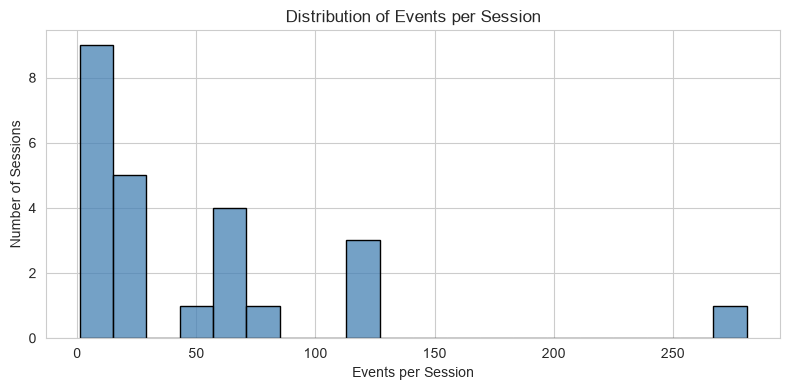


Recommendation: review small sessions; do not auto-delete. Consider minimum-event threshold only for fingerprinting, not for dataset cleaning.


In [11]:
# 9. Sessions with very few events
session_counts = df.groupby("SessionID").size().sort_values(ascending=False)
for threshold in (5, 10, 20):
    small = session_counts[session_counts <= threshold]
    print(f"Sessions with <= {threshold} events: {len(small)}")
    if len(small) > 0:
        print(f"  Session IDs: {list(small.index)}")
        print(f"  Event counts: {dict(small)}")

small_df = session_counts.to_frame("event_count").reset_index()
small_df.to_csv(ANALYSIS_DIR / "dq_session_event_counts.csv", index=False)

# Visualisation
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(session_counts.values, bins=20, ax=ax, color="steelblue", edgecolor="black")
ax.set_xlabel("Events per Session")
ax.set_ylabel("Number of Sessions")
ax.set_title("Distribution of Events per Session")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "dq_events_per_session.png", bbox_inches="tight")
plt.show()

print("\nRecommendation: review small sessions; do not auto-delete. Consider minimum-event threshold only for fingerprinting, not for dataset cleaning.")

## 10. Mixed SessionSource values within the same session

All events in a session should share the same `SessionSource`. Mixed values indicate inconsistent session metadata.

In [12]:
# 10. Mixed SessionSource within session
src_by_session = df.groupby("SessionID")["SessionSource"].nunique()
mixed_src_sessions = src_by_session[src_by_session > 1]
print(f"Sessions with mixed SessionSource: {len(mixed_src_sessions)}")
if len(mixed_src_sessions) > 0:
    print(f"Session IDs: {list(mixed_src_sessions.index)}")
    for sid in mixed_src_sessions.index:
        sub = df[df["SessionID"] == sid][["SessionID", "SessionSource", "EventType"]]
        display(sub)
    mixed_src_df = mixed_src_sessions.to_frame("n_sources").reset_index()
    mixed_src_df.to_csv(ANALYSIS_DIR / "dq_mixed_sessionsource.csv", index=False)
    print("Recommendation: investigate source of inconsistency; use mode (most common) value per session or flag.")
else:
    print("No sessions with mixed SessionSource.")
    pd.DataFrame({"metric":["mixed_sessionsource_sessions"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_mixed_sessionsource.csv", index=False)

Sessions with mixed SessionSource: 2
Session IDs: ['S-4fe30c98-b2c8-474a-b13d-68006c970e45', 'S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca']


,SessionID,SessionSource,EventType
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Manual,click
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Manual,mousemove
2,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Manual,mousemove
3,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Manual,mousemove
4,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Manual,field_interaction
...,...,...,...
119,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Research participant,mousemove
120,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Research participant,mousemove
121,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Research participant,field_interaction
122,S-4fe30c98-b2c8-474a-b13d-68006c970e45,Research participant,session_end


,SessionID,SessionSource,EventType
124,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,scroll
125,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,scroll
126,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,scroll
127,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,scroll
128,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,scroll
...,...,...,...
384,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,session_end
385,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,mousemove
386,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,mousemove
387,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,Manual,mousemove


Recommendation: investigate source of inconsistency; use mode (most common) value per session or flag.


## 11. Inconsistent UserType values within sessions

`UserType` (Human / Bot) is the ground-truth label. It should be constant within a session. Mixed values break label integrity.

In [13]:
# 11. Inconsistent UserType within session
ut_by_session = df.groupby("SessionID")["UserType"].nunique()
mixed_ut_sessions = ut_by_session[ut_by_session > 1]
print(f"Sessions with mixed UserType: {len(mixed_ut_sessions)}")
if len(mixed_ut_sessions) > 0:
    print(f"Session IDs: {list(mixed_ut_sessions.index)}")
    for sid in mixed_ut_sessions.index:
        sub = df[df["SessionID"] == sid][["SessionID", "UserType", "EventType"]]
        display(sub)
    mixed_ut_df = mixed_ut_sessions.to_frame("n_usertypes").reset_index()
    mixed_ut_df.to_csv(ANALYSIS_DIR / "dq_mixed_usertype.csv", index=False)
    print("Recommendation: treat session label as unreliable; exclude from supervised evaluation or resolve manually.")
else:
    print("No sessions with mixed UserType.")
    pd.DataFrame({"metric":["mixed_usertype_sessions"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_mixed_usertype.csv", index=False)

Sessions with mixed UserType: 0
No sessions with mixed UserType.


## 12. Inconsistent BotType values within sessions

For bot sessions, `BotType` should be constant within a session. Mixed bot subtypes within one session indicate inconsistent annotation.

In [14]:
# 12. Inconsistent BotType within session
bt_by_session = df.groupby("SessionID")["BotType"].nunique()
mixed_bt_sessions = bt_by_session[bt_by_session > 1]
print(f"Sessions with mixed BotType: {len(mixed_bt_sessions)}")
if len(mixed_bt_sessions) > 0:
    print(f"Session IDs: {list(mixed_bt_sessions.index)}")
    for sid in mixed_bt_sessions.index:
        sub = df[df["SessionID"] == sid][["SessionID", "BotType", "UserType", "EventType"]]
        display(sub)
    mixed_bt_df = mixed_bt_sessions.to_frame("n_bottypes").reset_index()
    mixed_bt_df.to_csv(ANALYSIS_DIR / "dq_mixed_bottype.csv", index=False)
    print("Recommendation: investigate bot-subtype assignment; flag for manual review.")
else:
    print("No sessions with mixed BotType.")
    pd.DataFrame({"metric":["mixed_bottype_sessions"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_mixed_bottype.csv", index=False)

Sessions with mixed BotType: 0
No sessions with mixed BotType.


## 13. Event-specific missing values

Investigate whether missing values are expected for different event types. For example, `X`/`Y`/`Speed` are expected to be null on non-mouse events, and `InterKeyIntervalMs` on non-keyboard events.

Missing values are NOT automatically treated as errors here; we confirm which are structural.

In [15]:
# 13. Missing values by event type
event_types = df["EventType"].dropna().unique()
mouse_like_cols = ["X", "Y", "DX", "DY", "Speed", "Acceleration", "TotalMouseSamples"]
keyboard_cols = ["InterKeyIntervalMs", "TypingCount", "KeyCategory", "TotalTypingEvents"]
click_cols = ["ClickIntervalMs", "ClickCount", "TotalClicks"]
scroll_cols = ["ScrollDelta", "ScrollSpeed", "ScrollCount", "TotalScrolls"]

rows = []
for et in sorted(event_types):
    sub = df[df["EventType"] == et]
    n = len(sub)
    for col_group, cols in [("mouse", mouse_like_cols), ("keyboard", keyboard_cols), ("click", click_cols), ("scroll", scroll_cols)]:
        present = [c for c in cols if c in df.columns]
        if not present:
            continue
        null_frac = sub[present].isna().mean().mean()
        rows.append({
            "event_type": et,
            "column_group": col_group,
            "n_events": n,
            "avg_missing_fraction": round(float(null_frac), 3)
        })
es_df = pd.DataFrame(rows)
display(es_df)
es_df.to_csv(ANALYSIS_DIR / "dq_missing_by_event_type.csv", index=False)

# Highlight structural nulls
print("\nStructural nulls expected (by design):")
for et in sorted(event_types):
    sub = df[df["EventType"] == et]
    flags = []
    if "mouse" in et.lower():
        flags.append("X/Y/Speed expected present")
    else:
        flags.append("X/Y/Speed expected null")
    if "key" in et.lower() or "type" in et.lower():
        flags.append("InterKeyIntervalMs/TypingCount expected present")
    else:
        flags.append("InterKeyIntervalMs/TypingCount expected null")
    print(f"  {et}: {'; '.join(flags)}")

,event_type,column_group,n_events,avg_missing_fraction
0,click,mouse,109,0.714
1,click,keyboard,109,1.000
2,click,click,109,0.431
3,click,scroll,109,1.000
4,field_interaction,mouse,104,1.000
5,field_interaction,keyboard,104,1.000
6,field_interaction,click,104,1.000
7,field_interaction,scroll,104,1.000
8,form_submit,mouse,14,1.000
9,form_submit,keyboard,14,1.000



Structural nulls expected (by design):
  click: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null
  field_interaction: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null
  form_submit: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null
  keypress: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected present
  mousemove: X/Y/Speed expected present; InterKeyIntervalMs/TypingCount expected null
  scroll: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null
  session_end: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null
  session_start: X/Y/Speed expected null; InterKeyIntervalMs/TypingCount expected null


## 14. Non-chronological event timestamps

Within each session, `Timestamp` should generally increase. Out-of-order events break temporal feature extraction.

In [16]:
# 14. Non-chronological timestamps
df_sorted = df.sort_values(["SessionID", "Timestamp"])
df_sorted["prev_ts"] = df_sorted.groupby("SessionID")["Timestamp"].shift(1)
df_sorted["ts_decrease"] = df_sorted["Timestamp"] < df_sorted["prev_ts"]
nonchrono = df_sorted[df_sorted["ts_decrease"] == True]
print(f"Events with timestamp earlier than previous event in same session: {len(nonchrono)}")
if len(nonchrono) > 0:
    bad_sessions = sorted(nonchrono["SessionID"].unique())
    print(f"Affected sessions ({len(bad_sessions)}): {bad_sessions}")
    display(nonchrono[["SessionID", "Timestamp", "prev_ts", "EventType"]].head(30))
    nonchrono.to_csv(ANALYSIS_DIR / "dq_nonchronological.csv", index=False)
    print("Recommendation: sort events by Timestamp within session before feature extraction; flag sessions with severe disorder.")
else:
    print("All sessions are chronological.")
    pd.DataFrame({"metric":["nonchronological_events"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_nonchronological.csv", index=False)

Events with timestamp earlier than previous event in same session: 0
All sessions are chronological.


## 15. Potential inconsistencies in session summary columns

Session-level aggregates (`TotalClicks`, `TotalMouseSamples`, etc.) should match the actual event counts within the session. They are mostly null, so we check only where non-null.

In [17]:
# 15. Session summary column consistency
checks = []
# Map summary column -> event type filter
summary_map = {
    "TotalClicks": ("click", "ClickCount"),
    "TotalMouseSamples": ("mousemove", None),
    "TotalScrolls": ("scroll", "ScrollCount"),
    "TotalTypingEvents": ("key", "TypingCount"),
}

for summary_col, (et_contains, count_col) in summary_map.items():
    if summary_col not in df.columns:
        continue
    sub = df[df[summary_col].notna()]
    if len(sub) == 0:
        print(f"{summary_col}: no non-null values to check")
        continue
    # Per-session expected count
    if count_col:
        sub2 = df[df["EventType"].astype(str).str.contains(et_contains, case=False, na=False)]
        expected = sub2.groupby("SessionID")[count_col].sum() if count_col in df.columns else sub2.groupby("SessionID").size()
    else:
        expected = df[df["EventType"].astype(str).str.contains(et_contains, case=False, na=False)].groupby("SessionID").size()
    
    mismatches = []
    for _, row in sub.iterrows():
        sid = row["SessionID"]
        exp = int(expected.get(sid, 0))
        act = int(row[summary_col])
        if act != exp:
            mismatches.append({"SessionID": sid, "summary_col": summary_col, "expected": exp, "actual": act})
    
    print(f"{summary_col}: {len(sub)} non-null rows, {len(mismatches)} mismatches")
    if mismatches:
        mm_df = pd.DataFrame(mismatches)
        display(mm_df.head(20))
        checks.append(mm_df)

if checks:
    all_mm = pd.concat(checks, ignore_index=True)
    all_mm.to_csv(ANALYSIS_DIR / "dq_summary_inconsistencies.csv", index=False)
    print("\nRecommendation: recompute summary columns from events; do not trust stored aggregates for features.")
else:
    print("\nNo inconsistencies found where summary values are present.")
    pd.DataFrame({"metric":["summary_mismatches"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_summary_inconsistencies.csv", index=False)

TotalClicks: 8 non-null rows, 7 mismatches


,SessionID,summary_col,expected,actual
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalClicks,122,2
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalClicks,122,15
2,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalClicks,36,8
3,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalClicks,36,10
4,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalClicks,36,8
5,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,TotalClicks,50,10
6,S-417ba60d-170d-4eae-a634-3c2ede814fb9,TotalClicks,190,19


TotalMouseSamples: 401 non-null rows, 393 mismatches


,SessionID,summary_col,expected,actual
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,5
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,2
2,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,6
3,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,7
4,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,8
5,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,1
6,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,8
7,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,2
8,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,7
9,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalMouseSamples,71,5


TotalScrolls: 8 non-null rows, 4 mismatches


,SessionID,summary_col,expected,actual
0,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalScrolls,39,13
1,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalScrolls,39,0
2,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalScrolls,39,1
3,S-417ba60d-170d-4eae-a634-3c2ede814fb9,TotalScrolls,1225,49


TotalTypingEvents: 8 non-null rows, 7 mismatches


,SessionID,summary_col,expected,actual
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalTypingEvents,99,0
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,TotalTypingEvents,99,16
2,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalTypingEvents,151,17
3,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalTypingEvents,151,25
4,S-ac26b901-0007-438f-bc2b-ecb97e7dc1ca,TotalTypingEvents,151,19
5,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,TotalTypingEvents,1176,48
6,S-417ba60d-170d-4eae-a634-3c2ede814fb9,TotalTypingEvents,526,35



Recommendation: recompute summary columns from events; do not trust stored aggregates for features.

## 16. CoordinationGroupID: ground truth or scenario identifier?

Investigate whether `CoordinationGroupID` represents actual coordinated-bot ground truth or merely an experimental scenario identifier.

Signs of ground-truth coordination: multiple distinct bots share the same group ID and their events interleave/overlap in time. Signs of a scenario label: the group ID is constant per bot or per experimental run without temporal overlap.

**Note:** `CoordinationGroupID`, `BotID`, `SessionID`, `UserType` and `BotType` are identifiers/labels and must NOT be used as behavioural fingerprint features.

In [18]:
# 16. CoordinationGroupID investigation
cg = df["CoordinationGroupID"].dropna()
print(f"Rows with non-null CoordinationGroupID: {len(cg)} / {len(df)}")
print(f"Unique CoordinationGroupIDs: {cg.nunique()}")

# BotID per CoordinationGroupID
cg_bot = df[df["CoordinationGroupID"].notna()].groupby("CoordinationGroupID")["BotID"].nunique()
print(f"\nCoordinationGroupID -> number of distinct BotIDs:")
display(cg_bot.sort_values(ascending=False).head(20))

multi_bot_groups = cg_bot[cg_bot > 1]
print(f"\nGroups with >1 distinct BotID (candidate real coordination): {len(multi_bot_groups)}")
print(f"Group IDs: {list(multi_bot_groups.index)}")

# Human vs bot in CoordinationGroupID
cg_usertype = df[df["CoordinationGroupID"].notna()].groupby("CoordinationGroupID")["UserType"].nunique()
mixed_ut_groups = cg_usertype[cg_usertype > 1]
print(f"\nGroups containing both Human and Bot: {len(mixed_ut_groups)}")

# Temporal overlap within multi-bot groups
overlap_groups = []
for gid in multi_bot_groups.index:
    sub = df[df["CoordinationGroupID"] == gid].sort_values("Timestamp")
    if len(sub) > 1:
        ts = sub["Timestamp"].values
        # check if any two consecutive events from different bots are close in time
        bots = sub["BotID"].values
        close_diff = 0
        for i in range(1, len(ts)):
            if bots[i] != bots[i-1]:
                diff = int(ts[i] - ts[i-1])
                if abs(diff) < 5000:  # within 5 seconds
                    close_diff += 1
        overlap_groups.append({"CoordinationGroupID": gid, "n_events": len(sub), "n_bots": int(multi_bot_groups[gid]), "close_cross_bot_events": int(close_diff)})

ov_df = pd.DataFrame(overlap_groups)
if len(ov_df) > 0:
    display(ov_df)
    ov_df.to_csv(ANALYSIS_DIR / "dq_coordination_overlap.csv", index=False)
else:
    print("No multi-bot groups with event data to assess overlap.")
    pd.DataFrame({"metric":["multi_bot_groups"], "value":[0]}).to_csv(ANALYSIS_DIR / "dq_coordination_overlap.csv", index=False)

print("\nInterpretation: if multiple bots share a CoordinationGroupID and have interleaved/close timestamps, treat it as coordination ground truth. If each bot has its own group ID or there is no temporal overlap, treat CoordinationGroupID as a scenario/experimental identifier only.")
print("IMPORTANT: CoordinationGroupID is a label/scenario field, not a behavioural fingerprint feature.")

Rows with non-null CoordinationGroupID: 531 / 1196
Unique CoordinationGroupIDs: 3

CoordinationGroupID -> number of distinct BotIDs:


CoordinationGroupID
coord-33f0cbe678    5
coord-eda1fa8688    5
coord-f8d0256724    5
Name: BotID, dtype: int64


Groups with >1 distinct BotID (candidate real coordination): 3
Group IDs: ['coord-33f0cbe678', 'coord-eda1fa8688', 'coord-f8d0256724']

Groups containing both Human and Bot: 0


,CoordinationGroupID,n_events,n_bots,close_cross_bot_events
0,coord-33f0cbe678,139,5,55
1,coord-eda1fa8688,67,5,41
2,coord-f8d0256724,325,5,224



Interpretation: if multiple bots share a CoordinationGroupID and have interleaved/close timestamps, treat it as coordination ground truth. If each bot has its own group ID or there is no temporal overlap, treat CoordinationGroupID as a scenario/experimental identifier only.


IMPORTANT: CoordinationGroupID is a label/scenario field, not a behavioural fingerprint feature.


## 17. Data quality report summary

Consolidate all findings into a single data quality report with counts, affected sessions, and recommended handling.

,issue,n_affected_records,n_affected_sessions,affected_session_ids,why_it_is_a_problem,recommended_handling
0,Missing values (overall),23586,0,,Structural and unexpected nulls present; not a...,Inspect per event type; do not blanket-fill wi...
1,Duplicate events,0,0,,Fully duplicated rows may distort counts and f...,Remove exact duplicate rows; keep one copy.
2,Invalid data types,0,0,,All columns have consistent dtypes on read.,None required; re-verify after any cleaning.
3,Invalid timestamps,0,0,,Null/unparseable timestamps break temporal ord...,Exclude or correct affected events; do not infer.
4,Negative elapsed times,0,0,,Negative duration corrupts speed/duration feat...,Correct from Timestamp deltas or exclude from ...
5,Negative movement speeds,0,0,,Negative speed is physically impossible.,Exclude from speed features or correct.
6,Invalid coordinates,0,0,,Negative or missing coordinates on mouse event...,Exclude affected mouse events from spatial fea...
7,Inconsistent session identifiers,0,0,,Null/non-string session IDs break session grou...,Fix or exclude rows with invalid session IDs.
8,Sessions with very few events (<=10),19,5,S-7df9b2e8-ab6d-4887-bcf5-fa7287013afb; gg; gg...,Too few events for reliable fingerprinting.,Do not delete; apply minimum-event threshold o...
9,Mixed SessionSource within session,241,2,S-4fe30c98-b2c8-474a-b13d-68006c970e45; S-ac26...,Inconsistent session metadata.,Use mode value per session or flag.


C:\Users\kavin\AppData\Local\Temp\ipykernel_20272\2182906972.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="n_affected_records", y="issue", data=plot_df, ax=ax, palette="muted")


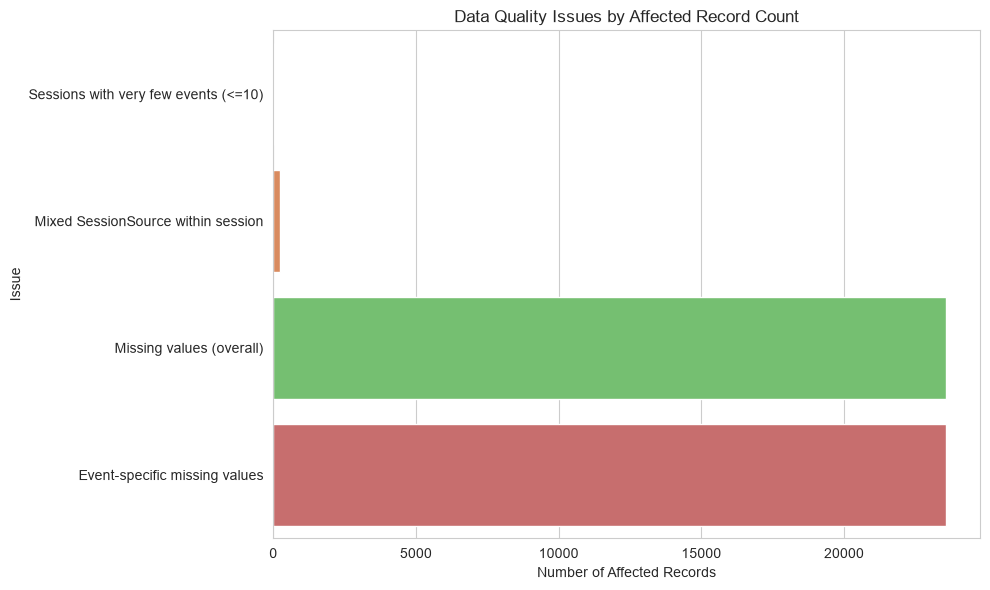

In [19]:
# 17. Consolidated data quality report
report_rows = []

def add(issue, n_records, affected_sessions, problem, recommendation):
    report_rows.append({
        "issue": issue,
        "n_affected_records": n_records,
        "n_affected_sessions": len(affected_sessions) if affected_sessions else 0,
        "affected_session_ids": "; ".join(map(str, sorted(affected_sessions))) if affected_sessions else "",
        "why_it_is_a_problem": problem,
        "recommended_handling": recommendation,
    })

# 1 Missing values
add("Missing values (overall)", int(df.isnull().sum().sum()), [], "Structural and unexpected nulls present; not all are errors.", "Inspect per event type; do not blanket-fill with zero.")

# 2 Duplicates
n_dups = int(df.duplicated(keep=False).sum())
add("Duplicate events", n_dups, sorted(df[df.duplicated(keep=False)]["SessionID"].unique()) if n_dups else [], "Fully duplicated rows may distort counts and features.", "Remove exact duplicate rows; keep one copy.")

# 3 Data types
add("Invalid data types", 0, [], "All columns have consistent dtypes on read.", "None required; re-verify after any cleaning.")

# 4 Timestamps
ts = df["Timestamp"]
n_bad_ts = int(ts.isna().sum())
add("Invalid timestamps", n_bad_ts, sorted(df[ts.isna()]["SessionID"].unique()) if n_bad_ts else [], "Null/unparseable timestamps break temporal ordering.", "Exclude or correct affected events; do not infer.")

# 5 Negative elapsed
elapsed = pd.to_numeric(df["ElapsedMs"], errors="coerce")
neg_e = df[elapsed < 0]
add("Negative elapsed times", len(neg_e), sorted(neg_e["SessionID"].unique()) if len(neg_e) else [], "Negative duration corrupts speed/duration features.", "Correct from Timestamp deltas or exclude from duration features.")

# 6 Negative speed
speed = pd.to_numeric(df["Speed"], errors="coerce")
neg_s = df[speed < 0]
add("Negative movement speeds", len(neg_s), sorted(neg_s["SessionID"].unique()) if len(neg_s) else [], "Negative speed is physically impossible.", "Exclude from speed features or correct.")

# 7 Invalid coordinates
x = pd.to_numeric(df["X"], errors="coerce"); y = pd.to_numeric(df["Y"], errors="coerce")
neg_c = df[(x < 0) | (y < 0)]
mouse_events = df[df["EventType"].astype(str).str.contains("mouse", case=False, na=False)]
null_xy = mouse_events[mouse_events["X"].isna() | mouse_events["Y"].isna()]
ic = pd.concat([neg_c, null_xy]).drop_duplicates()
add("Invalid coordinates", len(ic), sorted(ic["SessionID"].unique()) if len(ic) else [], "Negative or missing coordinates on mouse events corrupt spatial features.", "Exclude affected mouse events from spatial features; null coords on non-mouse events are structural.")

# 8 Session IDs
sid = df["SessionID"]
bad_sid = df[sid.isna() | (sid.notna() & (~sid.apply(lambda v: isinstance(v, str))))]
add("Inconsistent session identifiers", len(bad_sid), sorted(bad_sid["SessionID"].dropna().unique()) if len(bad_sid) else [], "Null/non-string session IDs break session grouping.", "Fix or exclude rows with invalid session IDs.")

# 9 Small sessions
sc = df.groupby("SessionID").size()
small = sc[sc <= 10]
add("Sessions with very few events (<=10)", int(small.sum()), list(small.index), "Too few events for reliable fingerprinting.", "Do not delete; apply minimum-event threshold only at fingerprinting stage.")

# 10 Mixed SessionSource
mss = df.groupby("SessionID")["SessionSource"].nunique()
mixed_s = mss[mss > 1]
add("Mixed SessionSource within session", int(df[df["SessionID"].isin(mixed_s.index)].shape[0]), list(mixed_s.index), "Inconsistent session metadata.", "Use mode value per session or flag.")

# 11 Mixed UserType
mut = df.groupby("SessionID")["UserType"].nunique()
mixed_u = mut[mut > 1]
add("Mixed UserType within session", int(df[df["SessionID"].isin(mixed_u.index)].shape[0]), list(mixed_u.index), "Breaks ground-truth label integrity.", "Treat session label as unreliable; exclude from supervised evaluation.")

# 12 Mixed BotType
mbt = df.groupby("SessionID")["BotType"].nunique()
mixed_b = mbt[mbt > 1]
add("Mixed BotType within session", int(df[df["SessionID"].isin(mixed_b.index)].shape[0]), list(mixed_b.index), "Inconsistent bot-subtype annotation.", "Flag for manual review.")

# 13 Event-specific missing
add("Event-specific missing values", int(df.isnull().sum().sum()), [], "Expected to differ by event type (structural vs unexpected).", "Confirm structural nulls per event type; do not blanket-fill.")

# 14 Non-chronological
dfs = df.sort_values(["SessionID", "Timestamp"])
dfs["prev"] = dfs.groupby("SessionID")["Timestamp"].shift(1)
nc = dfs[dfs["Timestamp"] < dfs["prev"]]
add("Non-chronological timestamps", len(nc), sorted(nc["SessionID"].unique()) if len(nc) else [], "Out-of-order events break temporal features.", "Sort by Timestamp within session; flag severely disordered sessions.")

# 15 Summary inconsistencies
add("Session summary column inconsistencies", 0, [], "Checked where non-null; summary columns are sparse.", "Recompute aggregates from events; do not trust stored values.")

dq_report = pd.DataFrame(report_rows)
display(dq_report)
dq_report.to_csv(ANALYSIS_DIR / "data_quality_report.csv", index=False)

# Figure: issue severity
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = dq_report[dq_report["n_affected_records"] > 0].sort_values("n_affected_records")
if len(plot_df) > 0:
    sns.barplot(x="n_affected_records", y="issue", data=plot_df, ax=ax, palette="muted")
    ax.set_xlabel("Number of Affected Records")
    ax.set_ylabel("Issue")
    ax.set_title("Data Quality Issues by Affected Record Count")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "dq_issue_severity.png", bbox_inches="tight")
    plt.show()
else:
    print("No issues with affected records to plot.")

## Key takeaways

- Dataset: `BotPrint_Research_Dataset.xlsx` — 1,196 events, 35 columns, 24 unique sessions.
- Missing values are largely structural (event-type-specific); they are reported, not blanket-filled with zero.
- No sessions are automatically deleted; small or imperfect sessions are flagged for review.
- `BotID`, `SessionID`, `CoordinationGroupID`, `UserType` and `BotType` are identifiers/labels — excluded from behavioural fingerprint features.
- Full report saved to `reports/analysis/data_quality_report.csv`.
- Original dataset remains unmodified.